In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.shape

(2443651, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
## Part 1: Best-Seller Trends Across Categories
### 1.1 Crosstab Analysis

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
bestseller_share = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
bestseller_share.sort_values(by=True, ascending=False).head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


In [9]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

bestseller_share = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
bestseller_share.sort_values(by=True, ascending=False).head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


In [10]:
chi2, p_value, dof, expected = stats.chi2_contingency(crosstab)
print("Chi-square:", chi2)
print("p-value:", p_value)

Chi-square: 36540.20270061387
p-value: 0.0


In [11]:
n = crosstab.to_numpy().sum()
r, c = crosstab.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, c) - 1)))
print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


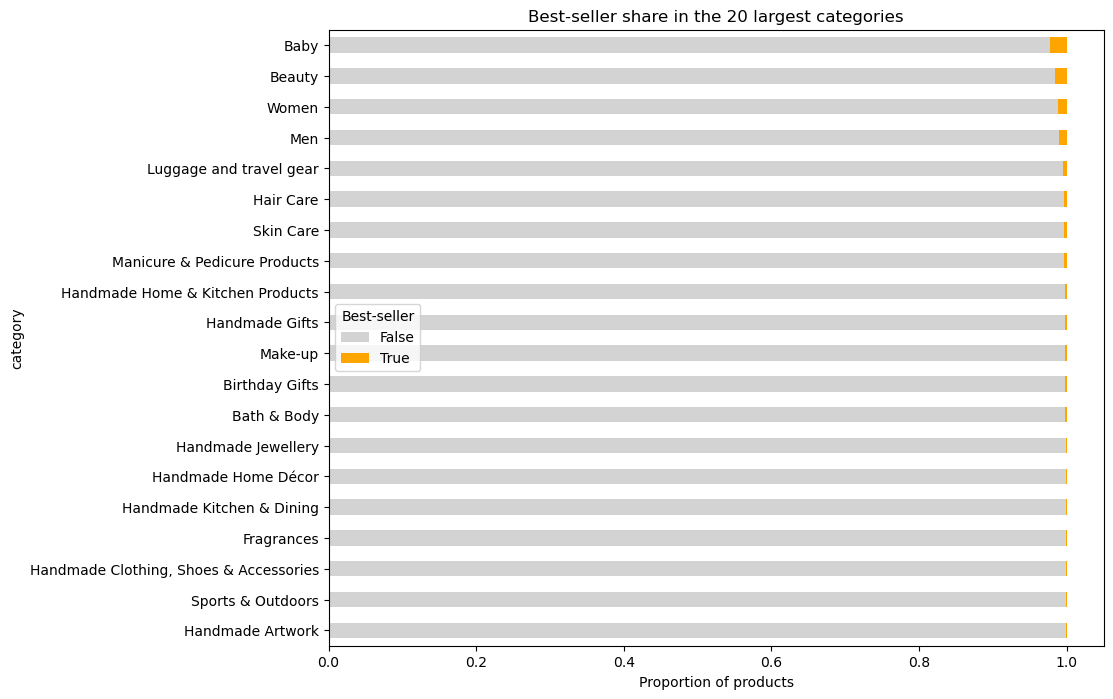

In [12]:
top20_cats = df['category'].value_counts().head(20).index

bestseller_share.loc[top20_cats].sort_values(by=True).plot(
    kind='barh', stacked=True, figsize=(10, 8), color=['lightgrey', 'orange']
)
plt.title("Best-seller share in the 20 largest categories")
plt.xlabel("Proportion of products")
plt.legend(title="Best-seller")
plt.show()

In [13]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no = df[(df['price'] >= lower) & (df['price'] <= upper)]

print("Lower bound:", lower, "| Upper bound:", upper)
print("Rows before:", len(df), "| after:", len(df_no))


Lower bound: -44.01 | Upper bound: 99.99000000000001
Rows before: 2443651 | after: 2115963


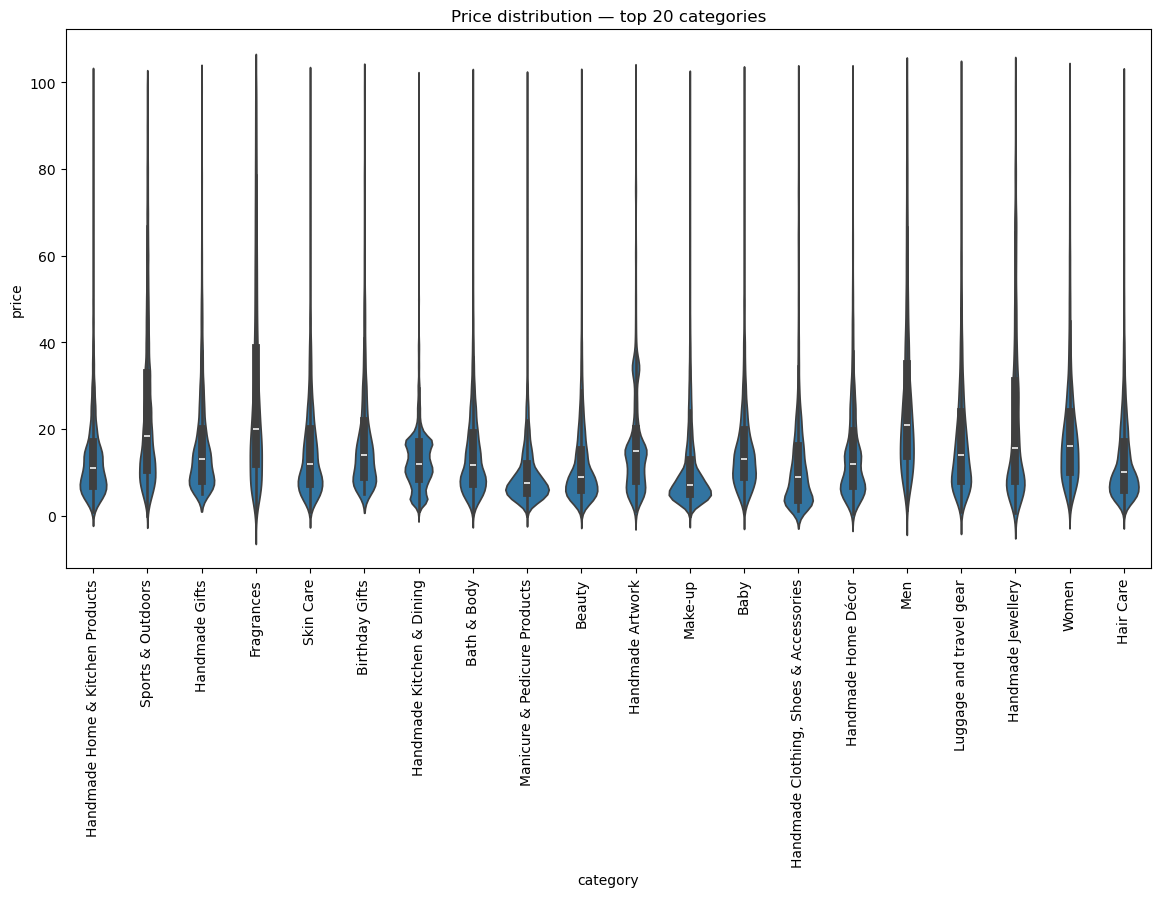

In [14]:
top20_no = df_no['category'].value_counts().head(20).index

plt.figure(figsize=(14, 7))
sns.violinplot(data=df_no[df_no['category'].isin(top20_no)], x='category', y='price')
plt.xticks(rotation=90)
plt.title("Price distribution — top 20 categories")
plt.show()

In [15]:
df_no.groupby('category')['price'].median().sort_values(ascending=False).head(5)

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

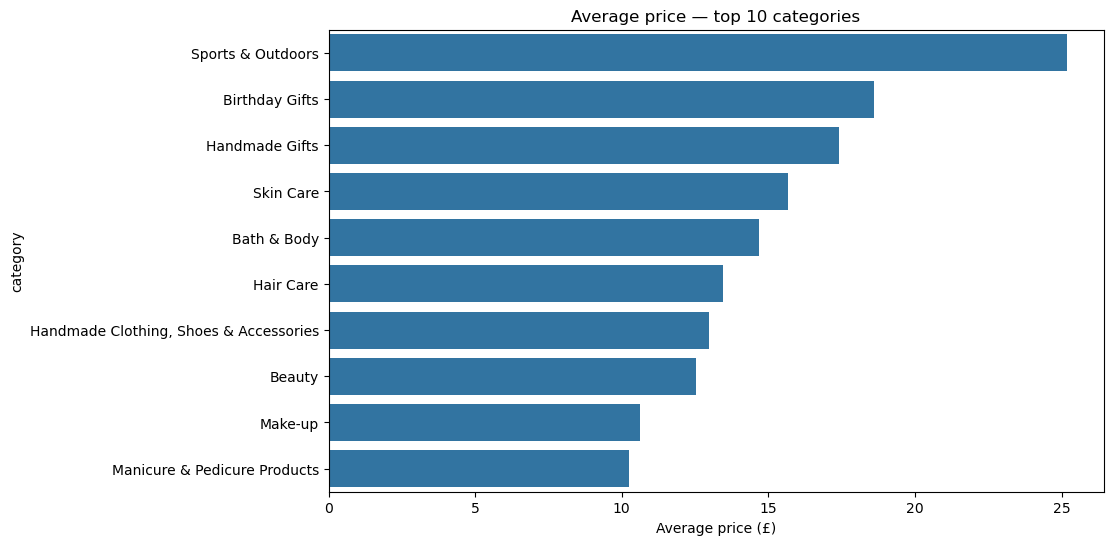

In [16]:
top10_no = df_no['category'].value_counts().head(10).index

avg_price_top10 = (df_no[df_no['category'].isin(top10_no)]
                   .groupby('category')['price'].mean()
                   .sort_values(ascending=False))

plt.figure(figsize=(10, 6))
sns.barplot(x=avg_price_top10.values, y=avg_price_top10.index)
plt.title("Average price — top 10 categories")
plt.xlabel("Average price (£)")
plt.show()

In [17]:
df_no.groupby('category')['price'].mean().sort_values(ascending=False).head(5)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

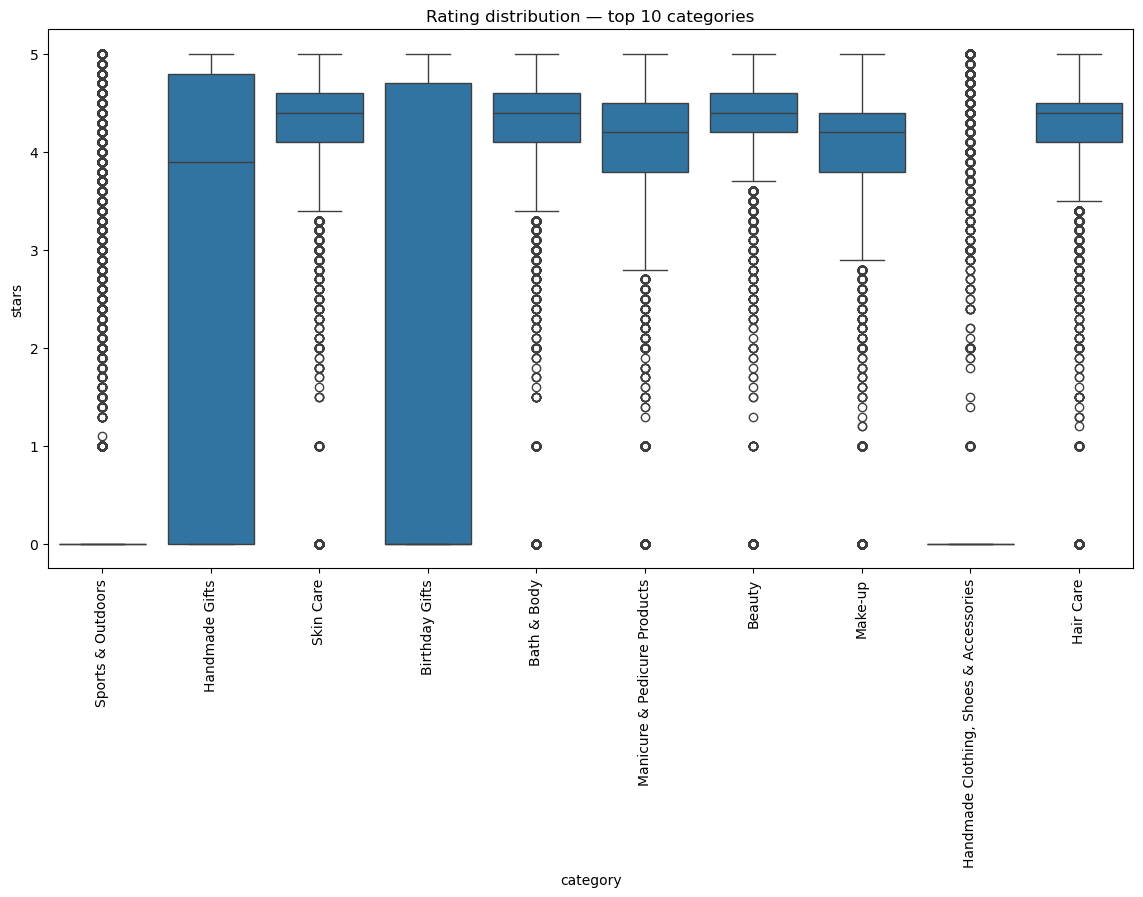

In [18]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_no[df_no['category'].isin(top10_no)], x='category', y='stars')
plt.xticks(rotation=90)
plt.title("Rating distribution — top 10 categories")
plt.show()

In [19]:
df_no.groupby('category')['stars'].median().sort_values(ascending=False).head(5)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [20]:
pearson = df_no['price'].corr(df_no['stars'])
spearman = df_no['price'].corr(df_no['stars'], method='spearman')
print("Pearson:", pearson)
print("Spearman:", spearman)

Pearson: -0.0776729987818131
Spearman: -0.06679697280768324


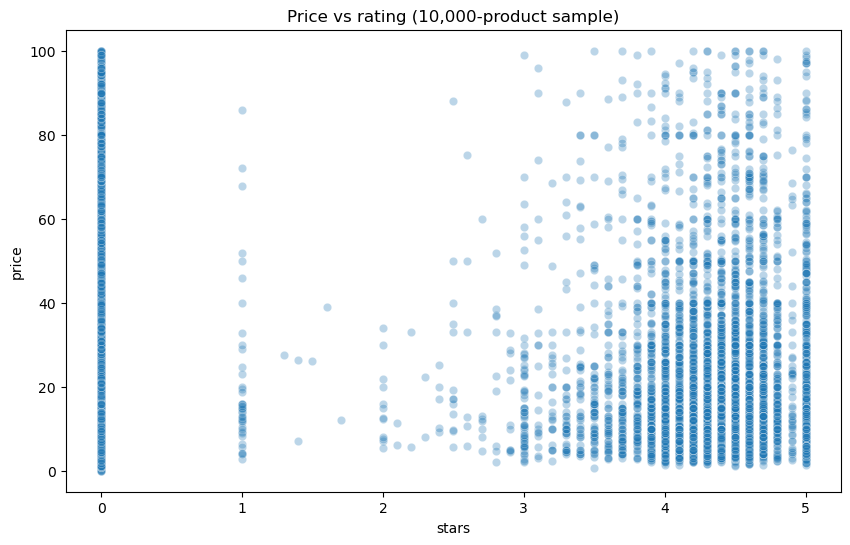

In [21]:
sample = df_no.sample(10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x='stars', y='price', alpha=0.3)
plt.title("Price vs rating (10,000-product sample)")
plt.show()

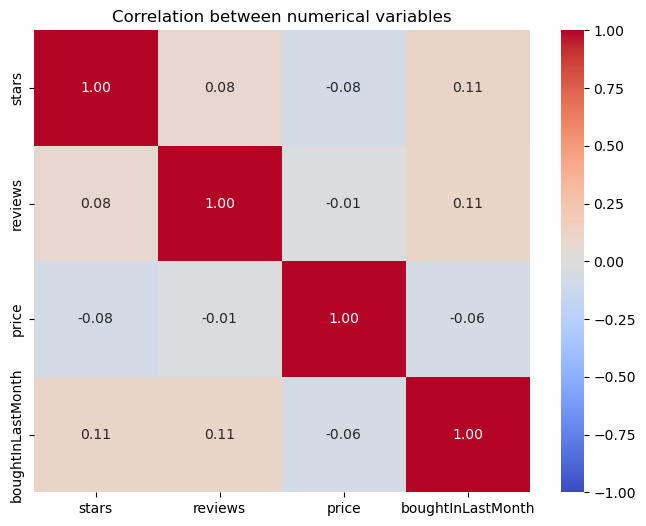

In [22]:
numeric = df_no.select_dtypes(include='number').drop(columns='uid')

plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between numerical variables")
plt.show()

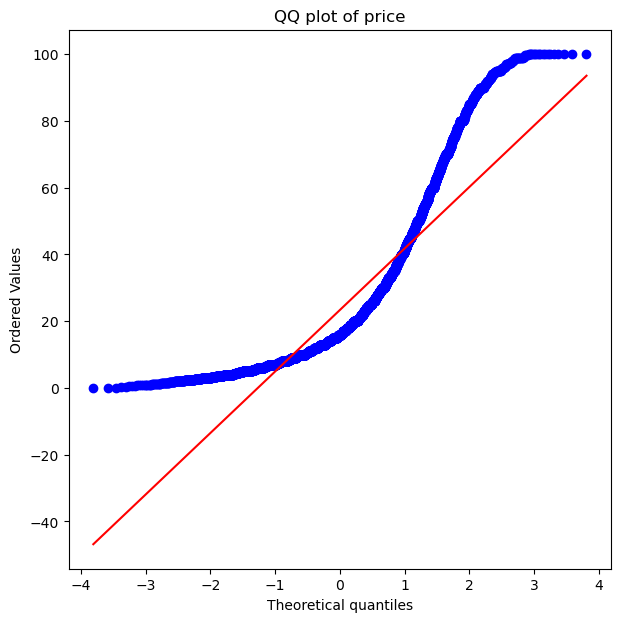

In [23]:
plt.figure(figsize=(7, 7))
stats.probplot(sample['price'], dist='norm', plot=plt)
plt.title("QQ plot of price")
plt.show()

In [25]:
"""

## Business Report: Amazon UK Product Insights

**1. Best-sellers by category**
Categories with the highest best-seller share are ___, ___ and ___ (___%).
The Chi-square test (p = ___) shows category and best-seller status are related,
but Cramér's V of ___ shows the relationship is ___.
*Business meaning:* ___

**2. Prices across categories**
After removing outliers (prices above £___), ___ has the highest median price
and ___ the highest average price.
*Business meaning:* ___

**3. Ratings across categories**
___ has the highest median rating. Note: unreviewed products show 0 stars.

**4. Price vs rating**
Correlation is ___ (Pearson) / ___ (Spearman): a higher price does / does not
mean a better rating. Prices are not normally distributed (right-skewed).
*Business meaning:* ___

**5. Bonus: with outliers**
___

"""

"\n\n## Business Report: Amazon UK Product Insights\n\n**1. Best-sellers by category**\nCategories with the highest best-seller share are ___, ___ and ___ (___%).\nThe Chi-square test (p = ___) shows category and best-seller status are related,\nbut Cramér's V of ___ shows the relationship is ___.\n*Business meaning:* ___\n\n**2. Prices across categories**\nAfter removing outliers (prices above £___), ___ has the highest median price\nand ___ the highest average price.\n*Business meaning:* ___\n\n**3. Ratings across categories**\n___ has the highest median rating. Note: unreviewed products show 0 stars.\n\n**4. Price vs rating**\nCorrelation is ___ (Pearson) / ___ (Spearman): a higher price does / does not\nmean a better rating. Prices are not normally distributed (right-skewed).\n*Business meaning:* ___\n\n**5. Bonus: with outliers**\n___\n\n"